In [2]:
import numpy as np
import scipy as sp
import pandas as pd
from urllib.request import urlopen
from io import BytesIO

import os
import pickle

from sklearn.model_selection import train_test_split


#import camda_functions#_FRANCISCO #import split_stratified_into_train_val_test

#from camda_functions import get_data, transforms, transforms_test, get_y_ordinal, split_stratified_into_train_val_test, train_and_save_binary_models
from camda_functions_2026 import get_tfidf, get_factorization, transforms, get_y_ordinal, save_pickle_model,load_from_pickle#,get_data,transforms_test
from camda_functions_2026 import split_stratified_into_train_val_test, train_and_save_binary_models,evaluate_models, results_report_phenotype,evaluate_models,sparse_fileter
from camda_functions_2026 import get_data2, transforms2, transforms_test2

In [6]:
def save_pickle_model(model_obj, file_path, model_name):    
    pkl_name = os.path.join(file_path, model_name)
    with open(pkl_name,'wb') as file:
        pickle.dump(model_obj,file)

def load_from_pickle(file_path, model_name):
    pkl_name = os.path.join(file_path, model_name)
    with open(pkl_name,'rb') as file:
        fact_model = pickle.load(file)
    
    return fact_model


In [7]:
from sklearn.decomposition import TruncatedSVD,NMF
def get_factorization(data, n_comp=100, nmf=True):
    if nmf==False:
        fact_model = TruncatedSVD(n_components=n_comp)
        fact_model.fit(data)
    else:
        fact_model = NMF(n_components = n_comp, init=None, max_iter=12000)
        fact_model.fit(data)
    
    return fact_model

In [3]:
metadata, counts = get_data2()

In [ ]:
metadata

,dataset,biosample,antibiotic,species,mic,phenotype,gtdb_species,gtdb_genus,gtdb_ani,adjusted_mic,adjusted_phenotype
accession,,,,,,,,,,,
BVBRC_1313.9821,c25_train,SAMEA677631,erythromycin,Streptococcus pneumoniae,64.0,resistant,Streptococcus pneumoniae,Streptococcus,0.988374,64.0,resistant
BVBRC_287.12440,c25_train c25_test,SAMN11110403,ceftazidime,Pseudomonas aeruginosa,64.0,resistant,Pseudomonas aeruginosa,Pseudomonas,0.993214,64.0,resistant
BVBRC_287.12441,c25_train c25_test,SAMN11110399,ceftazidime,Pseudomonas aeruginosa,64.0,resistant,Pseudomonas aeruginosa,Pseudomonas,0.992951,64.0,resistant
BVBRC_287.12442,c25_train c25_test,SAMN11110401,ceftazidime,Pseudomonas aeruginosa,128.0,resistant,Pseudomonas paraeruginosa,Pseudomonas,0.994432,128.0,resistant
BVBRC_287.12443,c25_train c25_test,SAMN11110400,ceftazidime,Pseudomonas aeruginosa,16.0,resistant,Pseudomonas aeruginosa,Pseudomonas,0.988773,16.0,intermediate
...,...,...,...,...,...,...,...,...,...,...,...
SRR5122323,c25_train,SAMN04901640,ceftazidime,Pseudomonas aeruginosa,64.0,resistant,Pseudomonas aeruginosa,Pseudomonas,0.988457,64.0,resistant
SRR5122332,c25_train,SAMN04901639,ceftazidime,Pseudomonas aeruginosa,64.0,resistant,Pseudomonas aeruginosa,Pseudomonas,0.993115,64.0,resistant
SRR8737371,c25_train c25_test,SAMN11110459,ceftazidime,Pseudomonas aeruginosa,256.0,resistant,Pseudomonas aeruginosa,Pseudomonas,0.993591,128.0,resistant


In [10]:
counts

NpzFile 'object' with keys: indices, indptr, format, shape, data

In [6]:
metadata["dataset"].unique()

array(['c25_train', 'c25_train c25_test', 'c24_train', 'c25_balance',
       'c25_test c25_balance', 'c24_test', 'c25_test',
       'c25_train c25_balance', 'c24_balance', 'c24_test c24_balance',
       'c24_train c24_balance', 'c25_train c25_test c25_balance'],
      dtype=object)

In [9]:
metadata["dataset"].str.contains("test",na=False).sum()

6655

In [5]:
metadata["adjusted_phenotype"].unique()

array(['resistant', 'intermediate', 'susceptible'], dtype=object)

In [ ]:
metadata["gtdb_genus"].unique()

array(['Streptococcus', 'Pseudomonas', 'Salmonella', 'Acinetobacter',
       'Klebsiella', 'Enterobacter', 'Escherichia', 'Staphylococcus',
       'Neisseria', 'Campylobacter'], dtype=object)

In [11]:
ruta_fact = "data_models/"# '/Users/vmac/cursos/estadistica_microbiomas/2024/camda2025/data_models/' # ruta para los datos de los modelos
n_comp = 100 #cuántos componentes?

# Gen Streptococcus

In [12]:
label_file = 'Streptococcus'

In [14]:
metadata_Streptococcus, counts_Streptococcus = sparse_fileter(counts, metadata ,label=label_file, antibiotic=False)

tfidf, tfidf_vect, amr_lsa= \
    transforms2(amr_count=counts_Streptococcus, data_label=label_file, only_counts = False, exist_fact = True,
                    exist_vect = True, fact_path = ruta_fact, n_comp = n_comp)


/miniconda3/envs/CMD26/lib/python3.9/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.4.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/miniconda3/envs/CMD26/lib/python3.9/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TruncatedSVD from version 1.4.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


amr inicia


In [16]:
Z = load_from_pickle(ruta_fact,"svd_Streptococcus.pkl")

tfidf_vect = load_from_pickle(ruta_fact,"tfidf_Streptococcus.pkl")
X = tfidf_vect.transform(counts_Streptococcus)
X= Z.transform(X)
Y= get_y_ordinal(metadata=metadata_Streptococcus, ordinal=False)

In [17]:
Y= get_y_ordinal(metadata=metadata_Streptococcus, ordinal=False)
X = amr_lsa

In [18]:
X = amr_lsa

X_train, y_train, __, __, X_test, y_test, class_w, __ = \
        split_stratified_into_train_val_test(X, Y, .80, 0, .20,
        std=False, two_subsets=True, random_state=42)

train_and_save_binary_models(X_train, y_train, label_file, output_dir="modelos_fenotipo")

Entrenando RandomForest...
Entrenando KNN...
Entrenando LogisticRegression...
Entrenando SVC...
Entrenando LASSO...


/miniconda3/envs/CMD26/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD26/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD26/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD26/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD26/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[('RandomForest',
  {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 50},
  0.8874381293736132),
 ('KNN', {'n_neighbors': 7, 'weights': 'distance'}, 0.8782172725721112),
 ('LogisticRegression', {'C': 10, 'solver': 'liblinear'}, 0.8837472264891619),
 ('SVC', {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}, 0.8957330602491893),
 ('LASSO', {'C': 10, 'solver': 'liblinear'}, 0.887425328554361)]

              precision    recall  f1-score   support

   resistant       0.86      0.90      0.88       130
 susceptible       0.90      0.87      0.88       142

    accuracy                           0.88       272
   macro avg       0.88      0.88      0.88       272
weighted avg       0.88      0.88      0.88       272



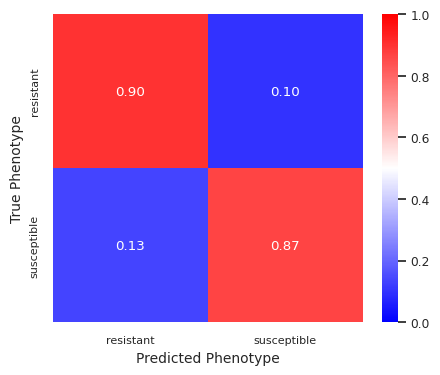

              precision    recall  f1-score   support

   resistant       0.91      0.88      0.89       130
 susceptible       0.90      0.92      0.91       142

    accuracy                           0.90       272
   macro avg       0.90      0.90      0.90       272
weighted avg       0.90      0.90      0.90       272



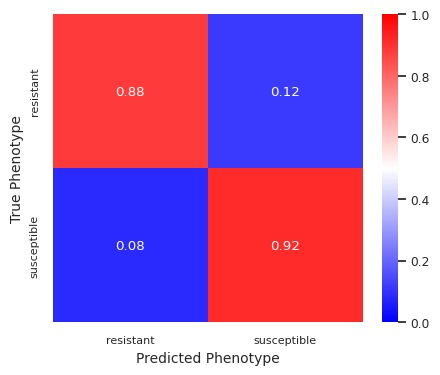

              precision    recall  f1-score   support

   resistant       0.87      0.89      0.88       130
 susceptible       0.90      0.88      0.89       142

    accuracy                           0.89       272
   macro avg       0.89      0.89      0.89       272
weighted avg       0.89      0.89      0.89       272



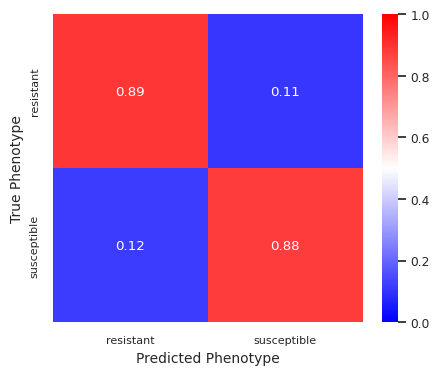

              precision    recall  f1-score   support

   resistant       0.88      0.87      0.87       130
 susceptible       0.88      0.89      0.88       142

    accuracy                           0.88       272
   macro avg       0.88      0.88      0.88       272
weighted avg       0.88      0.88      0.88       272



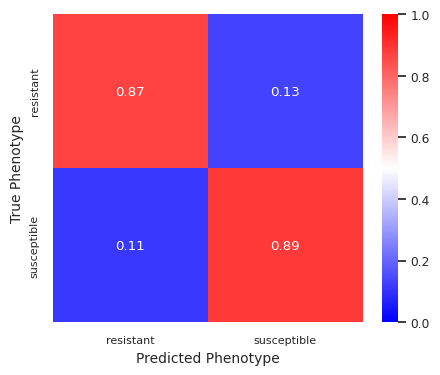

              precision    recall  f1-score   support

   resistant       0.88      0.89      0.89       130
 susceptible       0.90      0.89      0.89       142

    accuracy                           0.89       272
   macro avg       0.89      0.89      0.89       272
weighted avg       0.89      0.89      0.89       272



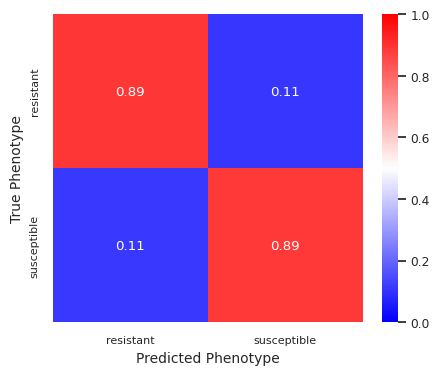

Scores guardados en 'modelos_fenotipo/scores_modelos.txt'.


,Modelo,Accuracy,F1 (weighted),F1 (macro),Precision (weighted),Recall (weighted)
0,RandomForest_Streptococcus,0.882353,0.882410,0.882296,0.883326,0.882353
1,SVC_Streptococcus,0.900735,0.900675,0.900432,0.900834,0.900735
2,LASSO_Streptococcus,0.886029,0.886071,0.885904,0.886328,0.886029
3,KNN_Streptococcus,0.878676,0.878655,0.878399,0.878658,0.878676
4,LogisticRegression_Streptococcus,0.889706,0.889736,0.889557,0.889862,0.889706


In [19]:
evaluate_models(X_test, y_test, data_label=label_file)

## erythromycin

In [ ]:
label_file = 'erythromycin'

In [13]:
from scipy.sparse import csr_matrix
def sparse_fileter (counts, metadata,label,antibiotic = True):
    """
    counts: a sparse matrix
    metadata: csv metadata
    label: antibiotic
    """
    if antibiotic == True:
        metadata_filtered = metadata[metadata["antibiotic"]==label]
        metadata_filtered = metadata_filtered[metadata_filtered["phenotype"]!='intermediate']
    
    else:   
    
        metadata_filtered = metadata[metadata["gtdb_genus"]==label]
        metadata_filtered = metadata_filtered[metadata_filtered["phenotype"]!='intermediate']
    
    # Reconstruir matriz sparse desde el npz
    counts_matrix = csr_matrix(
        (counts["data"], counts["indices"], counts["indptr"]),
        shape=counts["shape"]
    )
    # Obtener posiciones numéricas de las filas filtradas
    rows_to_keep = np.where(metadata.index.isin(metadata_filtered.index))[0]

    # Filtrar matriz sparse
    counts_filtered = counts_matrix[rows_to_keep]
    
    # filtrar columnas de zeros
    #cols_nonzero = np.array((counts_filtered != 0).sum(axis=0)).ravel() > 0

    #counts_filtered_reduced = counts_filtered[:, cols_nonzero]
    
    return  metadata_filtered, counts_filtered#_reduced

In [ ]:
metadata_erythromycin, counts_erythromycin = sparse_fileter(counts, metadata ,label=label_file)

In [ ]:
counts_erythromycin

<3178x7023103 sparse matrix of type '<class 'numpy.uint8'>'
	with 37548690 stored elements in Compressed Sparse Row format>

In [ ]:
metadata_erythromycin

In [ ]:
tfidf, tfidf_vect, amr_lsa= \
    transforms2(amr_count=counts_erythromycin, data_label=label_file, only_counts = False, exist_fact = True,
                    exist_vect = True, fact_path = ruta_fact, n_comp = n_comp)


/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TruncatedSVD from version 1.5.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [ ]:
Z = load_from_pickle(ruta_fact,"svd_erythromycin.pkl")

/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TruncatedSVD from version 1.5.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [ ]:
Z

TruncatedSVD(n_components=100)

In [ ]:
tfidf_vect = load_from_pickle(ruta_fact,"tfidf_erythromycin.pkl")
X = tfidf_vect.transform(counts_erythromycin)
X= Z.transform(X)
Y= get_y_ordinal(metadata=metadata_erythromycin, ordinal=False)

In [ ]:
Y= get_y_ordinal(metadata=metadata_erythromycin, ordinal=False)
X = amr_lsa

In [ ]:
#X = amr_lsa

X_train, y_train, __, __, X_test, y_test, class_w, __ = \
        split_stratified_into_train_val_test(X, Y, .80, 0, .20,
        std=False, two_subsets=True, random_state=42)

In [ ]:
train_and_save_binary_models(X_train, y_train, label_file, output_dir="modelos_fenotipo")

Entrenando RandomForest...
Entrenando KNN...
Entrenando LogisticRegression...
Entrenando SVC...
Entrenando LASSO...


/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/miniconda3/envs/CMD25/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[('RandomForest',
  {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100},
  np.float64(0.8548388843339574)),
 ('KNN',
  {'n_neighbors': 3, 'weights': 'distance'},
  np.float64(0.8442159243846975)),
 ('LogisticRegression',
  {'C': 10, 'solver': 'lbfgs'},
  np.float64(0.8355591479355846)),
 ('SVC',
  {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'},
  np.float64(0.8536539145769846)),
 ('LASSO', {'C': 10, 'solver': 'liblinear'}, np.float64(0.8406741642559906))]

              precision    recall  f1-score   support

   resistant       0.83      0.84      0.84       301
 susceptible       0.86      0.85      0.85       335

    accuracy                           0.85       636
   macro avg       0.85      0.85      0.85       636
weighted avg       0.85      0.85      0.85       636



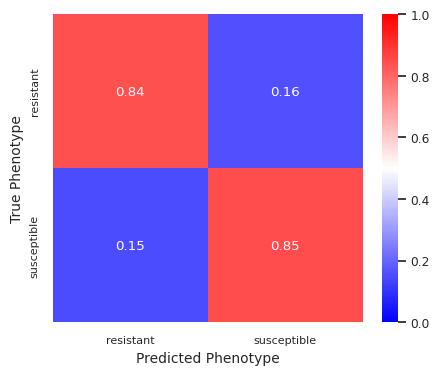

              precision    recall  f1-score   support

   resistant       0.83      0.81      0.82       301
 susceptible       0.83      0.85      0.84       335

    accuracy                           0.83       636
   macro avg       0.83      0.83      0.83       636
weighted avg       0.83      0.83      0.83       636



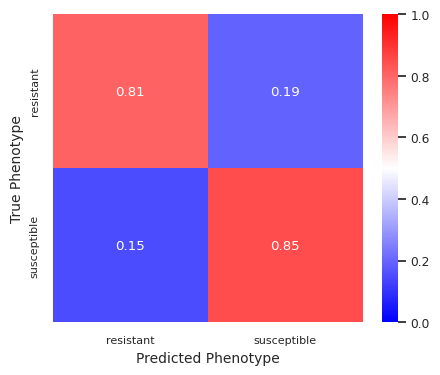

              precision    recall  f1-score   support

   resistant       0.86      0.83      0.84       301
 susceptible       0.85      0.87      0.86       335

    accuracy                           0.85       636
   macro avg       0.85      0.85      0.85       636
weighted avg       0.85      0.85      0.85       636



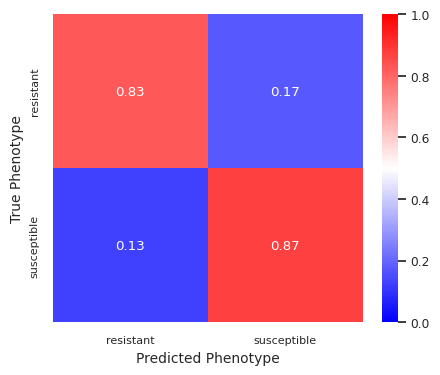

              precision    recall  f1-score   support

   resistant       0.84      0.84      0.84       301
 susceptible       0.85      0.86      0.86       335

    accuracy                           0.85       636
   macro avg       0.85      0.85      0.85       636
weighted avg       0.85      0.85      0.85       636



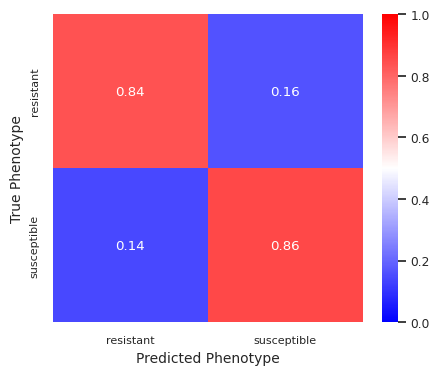

              precision    recall  f1-score   support

   resistant       0.84      0.81      0.83       301
 susceptible       0.84      0.86      0.85       335

    accuracy                           0.84       636
   macro avg       0.84      0.84      0.84       636
weighted avg       0.84      0.84      0.84       636



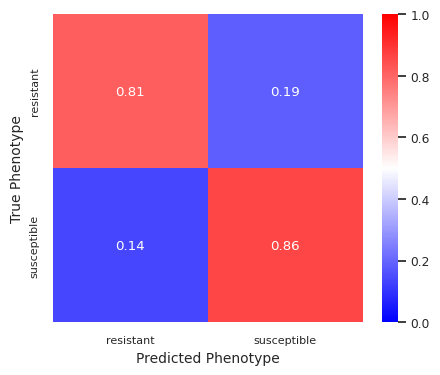

Scores guardados en 'modelos_fenotipo/scores_modelos.txt'.


,Modelo,Accuracy,F1 (weighted),F1 (macro),Precision (weighted),Recall (weighted)
0,LogisticRegression_erythromycin,0.845912,0.845936,0.845521,0.845978,0.845912
1,KNN_erythromycin,0.828616,0.828494,0.827901,0.828574,0.828616
2,RandomForest_erythromycin,0.852201,0.852040,0.851490,0.852302,0.852201
3,LASSO_erythromycin,0.847484,0.847471,0.847021,0.847462,0.847484
4,SVC_erythromycin,0.838050,0.837895,0.837307,0.838076,0.838050


In [ ]:
evaluate_models(X_test, y_test, data_label=label_file)

## ceftazidime

In [ ]:
label_file = 'ceftazidime'
metadata_ceftazidime, counts_ceftazidime = sparse_fileter(counts, metadata ,label=label_file)

In [ ]:
fidf, tfidf_vect, amr_lsa= \
    transforms(amr_count=counts_ceftazidime, data_label=label_file, only_counts = False, exist_fact = True,
                    exist_vect = True, fact_path = ruta_fact, n_comp = n_comp)

In [ ]:
Y= get_y_ordinal(metadata=metadata_ceftazidime, ordinal=False)
X = amr_lsa

X_train, y_train, __, __, X_test, y_test, class_w, __ = \
        split_stratified_into_train_val_test(X, Y, .80, 0, .20,
        std=False, two_subsets=True, random_state=42)

In [ ]:
train_and_save_binary_models(X_train, y_train, label_file, output_dir="modelos_fenotipo")
evaluate_models(X_test, y_test, data_label=label_file)

## meropenem

In [ ]:
label_file = 'meropenem'
metadata_meropenem, counts_meropenem = sparse_fileter(counts, metadata ,label=label_file)
fidf, tfidf_vect, amr_lsa= \
    transforms(amr_count=counts_meropenem, data_label=label_file, only_counts = False, exist_fact = True,
                    exist_vect = True, fact_path = ruta_fact, n_comp = n_comp)
Y= get_y_ordinal(metadata=metadata_meropenem, ordinal=False)
X = amr_lsa

X_train, y_train, __, __, X_test, y_test, class_w, __ = \
        split_stratified_into_train_val_test(X, Y, .80, 0, .20,
        std=False, two_subsets=True, random_state=42)

In [ ]:
train_and_save_binary_models(X_train, y_train, label_file, output_dir="modelos_fenotipo")
evaluate_models(X_test, y_test, data_label=label_file)